# 05. Продукт: сквозная проверка распознавания по WAV-файлам

**Цель:** проверить готовый продукт (`src/amc/infer.py`, ONNX-модель) так, как им будут пользоваться:
на WAV-записях с произвольной частотой дискретизации, несущей и скоростью, а не на подготовленных окнах датасета.
Здесь участвуют все звенья: чтение файла → поиск сигнала в спектре → перенос в ноль и передискретизация →
окна → нейросеть (ONNX) → агрегация → гибрид с ЦОС → физические единицы (Гц, Бод, дБ).

**Данные:** новые записи, которых модель не видела: генератор с другим seed, затем
- передискретизация в 4 раза (fs = 48 кГц), перенос на случайную несущую 3…20 кГц;
- белый шум по всей полосе записи (как в реальном приёмнике), ОСШ **в полосе сигнала** 0…25 дБ;
- канал генератора (многолучёвость, доплер, фазовый шум) — как при обучении;
- половина файлов — стерео I/Q, половина — моно (вещественный сигнал).

**Шаги:** 1) генерация тестового набора; 2) прогон продукта; 3) точность классификации по ОСШ;
4) точность параметров в физических единицах; 5) выводы.

In [1]:
import tempfile
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from scipy import signal as sps
from sklearn.metrics import confusion_matrix

from amc.generator import ANALOG, CLASSES, FSK, LINEAR, GenConfig, generate_one
from amc.infer import Classifier, analyze

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "product"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")


def savefig(name: str) -> None:
    """Сохранить рисунок."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

## 1. Тестовый набор
По 40 файлов на класс (440 файлов), длительность ≈ 0,7 с (8192 отсчёта при fs_base = 12 кГц → 32 768 при 48 кГц).

In [2]:
FS0, UP = 12000, 4
N_PER_CLASS = 40
cfg = replace(GenConfig(), n=8192, snr_db=(60.0, 60.0))  # шум добавляется ниже — в полосе записи
rng = np.random.default_rng(20261107)
tmp = Path(tempfile.mkdtemp(prefix="amc_product_"))
truth = []
for cls in CLASSES:
    for i in range(N_PER_CLASS):
        _, m, x = generate_one(cls, rng, cfg, return_clean=True)
        y = sps.resample_poly(x.astype(np.complex128), UP, 1)
        fc = rng.uniform(3000, 20000)
        y = y * np.exp(2j * np.pi * fc / (FS0 * UP) * np.arange(len(y)))
        snr_in = rng.uniform(0, 25)
        n0 = np.mean(np.abs(y) ** 2) / 10 ** (snr_in / 10) / (m["bw99"] * FS0)
        y = y + np.sqrt(n0 * FS0 * UP / 2) * (rng.standard_normal(len(y)) + 1j * rng.standard_normal(len(y)))
        y /= np.abs(y).max() * 1.05
        stereo = i % 2 == 0
        f = tmp / f"{cls}_{i:03d}.wav"
        if stereo:
            sf.write(f, np.stack([y.real, y.imag], 1).astype(np.float32), FS0 * UP, subtype="FLOAT")
        else:
            sf.write(f, y.real, FS0 * UP, subtype="PCM_16")
        truth.append({"file": f.name, "cls": cls, "stereo": stereo, "snr_inband": snr_in,
                      "carrier": fc + m["cfo"] * FS0, "rate": FS0 / m["sps"] if cls not in ANALOG else np.nan,
                      "bw99": m["bw99"] * FS0, "rolloff": m["rolloff"], "fsk_shift": m["fsk_shift"] * FS0,
                      "multipath": m["multipath"], "am_index": m["am_index"], "audio_bw": m["audio_bw"] * FS0})
T = pd.DataFrame(truth)
print(len(T), "файлов во временной папке")
T.describe().round(2)

440 файлов во временной папке <временная папка>


,snr_inband,carrier,rate,bw99,rolloff,fsk_shift,am_index,audio_bw
count,440.00,440.00,320.00,440.00,240.00,80.00,40.00,120.00
mean,12.87,11391.68,1636.51,1779.44,0.35,1082.44,0.59,783.51
std,7.03,4854.33,661.03,1005.59,0.09,554.87,0.19,386.09
min,0.01,2472.53,751.40,93.75,0.20,356.64,0.30,133.40
25%,7.04,7245.96,1043.25,1066.41,0.28,617.74,0.44,465.11
50%,12.82,11401.33,1509.74,1546.88,0.36,940.94,0.52,765.93
75%,18.76,15177.32,2154.29,2343.75,0.42,1459.56,0.76,1147.48
max,24.83,20483.87,2998.04,5625.00,0.50,2667.64,0.96,1434.92


## 2. Прогон продукта

In [3]:
clf = Classifier()
res = []
for f in T["file"]:
    r = analyze(tmp / f, clf)
    res.append({"file": f, "pred": r["modulation"], "conf": r["confidence"], "snr_est": r["snr_inband_dB"],
                "carrier_est": r["carrier_Hz"], "rate_est": r["symbol_rate_Bd"], "bw_est": r["bandwidth99_Hz"],
                "rolloff_est": r["rolloff"], "shift_est": r["fsk_shift_Hz"], "method": r["method"]["rate"], "scale": r["scale"],
                "fs_proc": r["processing_fs_Hz"]})
D = T.merge(pd.DataFrame(res), on="file")
D["верно"] = D["pred"] == D["cls"]
(ROOT / "reports" / "product_eval.csv").write_text(D.to_csv(index=False), encoding="utf-8")
print(f"accuracy: {D['верно'].mean():.3f}; стерео {D[D.stereo]['верно'].mean():.3f}, "
      f"моно {D[~D.stereo]['верно'].mean():.3f}")

accuracy: 0.752; стерео 0.777, моно 0.727


## 3. Классификация

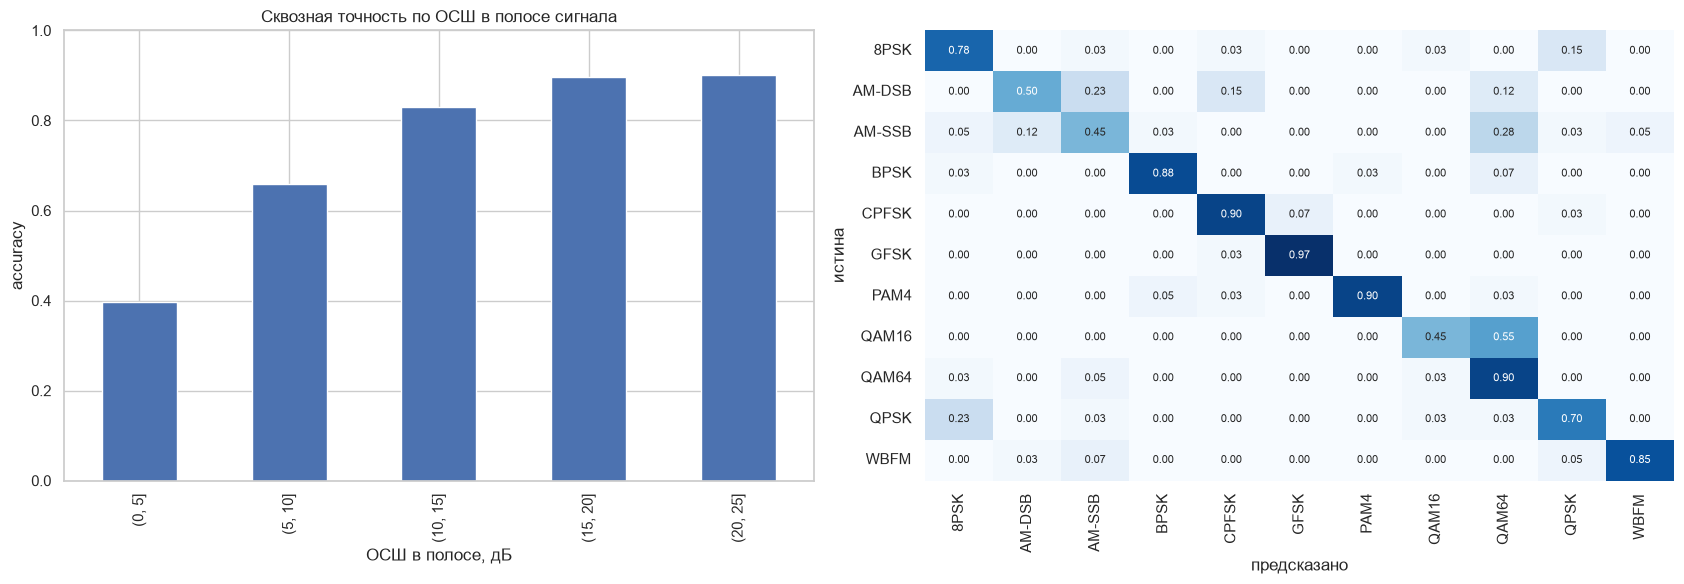

,accuracy,accuracy (многолучёвость),accuracy (один луч)
cls,,,
8PSK,0.775,0.696,0.882
AM-DSB,0.500,0.591,0.389
AM-SSB,0.450,0.520,0.333
BPSK,0.875,0.926,0.769
CPFSK,0.900,0.889,0.923
GFSK,0.975,1.000,0.933
PAM4,0.900,0.913,0.882
QAM16,0.450,0.217,0.765
QAM64,0.900,0.852,1.000


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
D["ОСШ в полосе, дБ"] = pd.cut(D["snr_inband"], [0, 5, 10, 15, 20, 25])
D.groupby("ОСШ в полосе, дБ", observed=True)["верно"].mean().plot.bar(ax=axes[0])
axes[0].set_ylabel("accuracy")
axes[0].set_ylim(0, 1)
axes[0].set_title("Сквозная точность по ОСШ в полосе сигнала")
cm = confusion_matrix(D["cls"], D["pred"], labels=CLASSES, normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False,
            annot_kws={"size": 8})
axes[1].set_xlabel("предсказано")
axes[1].set_ylabel("истина")
plt.tight_layout()
savefig("product_accuracy")
plt.show()
pd.DataFrame({"accuracy": D.groupby("cls")["верно"].mean(),
              "accuracy (многолучёвость)": D[D.multipath].groupby("cls")["верно"].mean(),
              "accuracy (один луч)": D[~D.multipath].groupby("cls")["верно"].mean()}).round(3)

## 4. Параметры в физических единицах
Ошибки считаются на файлах с **верно определённым** классом (для неверного класса параметр либо не выводится,
либо относится к другой модели сигнала). Для скорости, полосы и разноса — относительная ошибка, для несущей — в Гц
и в долях скорости/полосы, для ОСШ — в дБ.

In [5]:
C = D[D["верно"]].copy()
rows = []


def add(name: str, err: pd.Series, unit: str) -> None:
    """Строка сводки ошибок."""
    e = err.dropna().abs()
    rows.append({"параметр": name, "n": len(e), "медиана |ош.|": e.median(), "90-й перцентиль": e.quantile(0.9),
                 "единицы": unit})


add("ОСШ в полосе", C["snr_est"] - C["snr_inband"], "дБ")
add("несущая", C["carrier_est"] - C["carrier"], "Гц")
add("несущая / полоса", (C["carrier_est"] - C["carrier"]) / C["bw99"], "доли полосы")
dig = C[~C.cls.isin(ANALOG)]
add("символьная скорость", (dig["rate_est"] - dig["rate"]) / dig["rate"], "отн.")
add("полоса 99 %", (C["bw_est"] - C["bw99"]) / C["bw99"], "отн.")
lin = C[C.cls.isin(LINEAR)]
add("roll-off", lin["rolloff_est"] - lin["rolloff"], "абс.")
fsk = C[C.cls.isin(FSK)]
add("разнос ЧМн", (fsk["shift_est"] - fsk["fsk_shift"]) / fsk["fsk_shift"], "отн.")
P = pd.DataFrame(rows).set_index("параметр")
P.round(4)

,n,медиана |ош.|,90-й перцентиль,единицы
параметр,,,,
ОСШ в полосе,331,1.4191,4.0574,дБ
несущая,331,8.9066,241.4226,Гц
несущая / полоса,331,0.0054,0.1214,доли полосы
символьная скорость,259,0.0457,0.2269,отн.
полоса 99 %,331,0.0833,0.3103,отн.
roll-off,184,0.0386,0.1087,абс.
разнос ЧМн,75,0.0832,0.1540,отн.


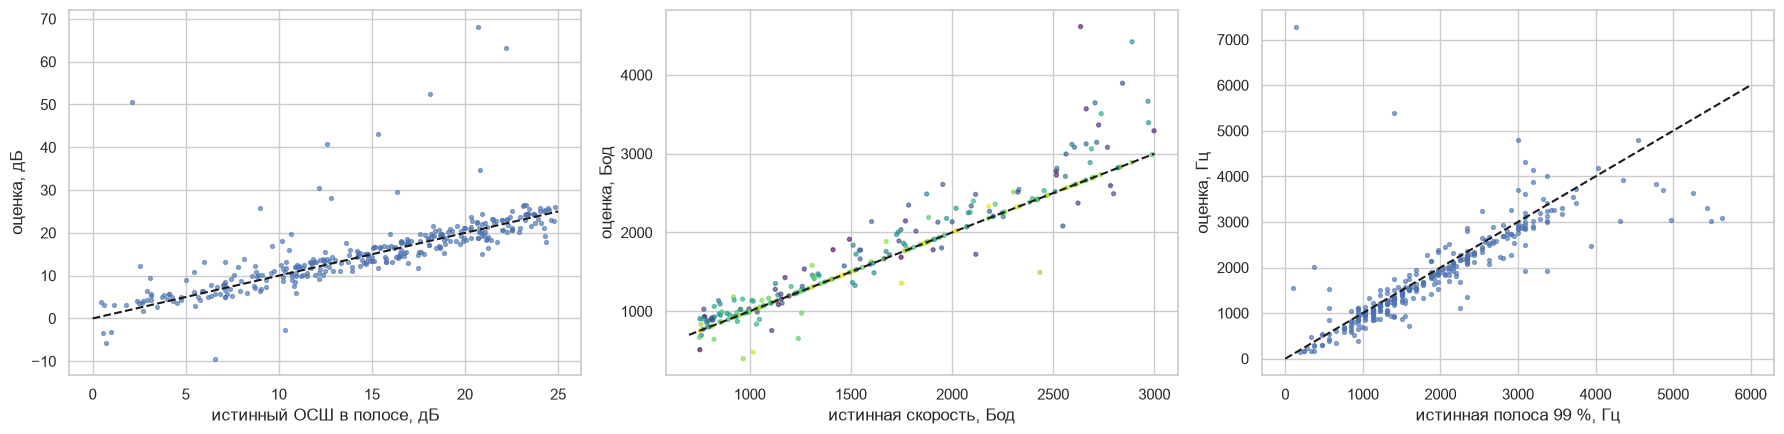

cls
8PSK     0.645
BPSK     0.486
CPFSK    0.167
GFSK     0.077
PAM4     0.556
QAM16    0.667
QAM64    0.417
QPSK     0.750
Name: ok, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].scatter(C["snr_inband"], C["snr_est"], s=8, alpha=0.6)
axes[0].plot([0, 25], [0, 25], "k--")
axes[0].set_xlabel("истинный ОСШ в полосе, дБ")
axes[0].set_ylabel("оценка, дБ")
axes[1].scatter(dig["rate"], dig["rate_est"], s=8, alpha=0.6, c=dig["snr_inband"], cmap="viridis")
axes[1].plot([700, 3000], [700, 3000], "k--")
axes[1].set_xlabel("истинная скорость, Бод")
axes[1].set_ylabel("оценка, Бод")
axes[2].scatter(C["bw99"], C["bw_est"], s=8, alpha=0.6)
axes[2].plot([0, 6000], [0, 6000], "k--")
axes[2].set_xlabel("истинная полоса 99 %, Гц")
axes[2].set_ylabel("оценка, Гц")
plt.tight_layout()
savefig("product_params")
plt.show()
# по видам модуляции: доля оценок скорости с ошибкой < 1 %
dig.assign(ok=((dig["rate_est"] - dig["rate"]).abs() / dig["rate"] < 0.01)).groupby("cls")["ok"].mean().round(3)

## 5. Выводы

**Сквозная точность продукта** на 440 новых WAV (fs 48 кГц, случайные несущая, скорость, канал, ОСШ в полосе
0…25 дБ): **75,2 %**; по ОСШ в полосе сигнала — 40 % (0–5 дБ), 66 % (5–10), 83 % (10–15), 90 % (15–20),
90 % (20–25). Стерео (I/Q) 77,7 %, моно (вещественный сигнал) 72,7 % — путь вещественного сигнала работает.
Для сравнения: полоса сигнала — ≈ 15 % полосы обработки, поэтому ОСШ в полосе на ≈ 8 дБ выше ОСШ во всей полосе
обработки (так ОСШ определён при обучении). Точность той же модели на её собственном тесте: 81 % при 0–5 дБ,
88 % при 5–10 дБ, 90 % при 10–15 дБ (≈ 8–13, 13–18, 18–23 дБ в полосе). Продукт при 10–15 и 15–20 дБ в полосе
даёт 83 и 90 % — **потери конвейера** (поиск сигнала, перенос, передискретизация) **невелики**.

**Найдено и исправлено сквозной проверкой** (на тесте окон датасета этих ошибок не видно в принципе):
1. моно-файлы: у аналитического сигнала отрицательные частоты пусты → «пол шума» ≈ 0 → весь шум
   принимался за сигнал, передискретизации не было; моно 20 % → 72 % после оценки только по f > 0;
2. АМ с малой глубиной: видна только линия несущей (полоса 2–5 бинов) → сигнал «сжимался», боковые полосы
   срезались → поиск масштаба по **самосогласованности** (регрессионная голова сети сама оценивает долю
   полосы; выбирается масштаб, где она ближе к обучающей 15 %); AM-DSB 37,5 % → 50 %. Вариант «выбирать масштаб
   по максимуму уверенности» проверен и отвергнут: общая точность падала до 65,7 % — сеть бывает уверенно
   неправа на чужом масштабе (типичная проблема калибровки вне распределения обучения).
   Вариант «снимать линии медианным фильтром» тоже проверен и отвергнут (71,8 %).

**Слабые места:** AM-DSB (50 %) и AM-SSB (45 %): при сильном шуме и малой глубине модуляции от АМ остаётся
несущая, неотличимая от тона других классов; AM-SSB путается с QAM64 даже при верном масштабе. QAM16 ↔ QAM64 —
известная трудная пара (как и в 02/03), особенно при многолучёвости (QAM16: 22 % против 77 % в одном луче) —
продукт не содержит эквалайзера; это главное направление развития.

**Параметры** (файлы с верным классом): несущая — медиана ошибки 9 Гц (0,5 % полосы); ОСШ в полосе — 1,4 дБ;
полоса 99 % — 8 %; roll-off — 0,04; разнос ЧМн — 8 %.

**Символьная скорость** — три варианта гибрида проверены последовательно:
1. единый порог «ЦОС при ОСШ сети > 0 дБ»: медиана 7,3 %, 90-й перцентиль 52 % (срывы ЦОС при 0…10 дБ);
2. пороги, выбранные на val в 03b (скорость — ЦОС только при > 10 дБ): медиана 9,3 %, 90-й перцентиль 20 %;
3. **каскад «сеть → ЦОС»** (итоговый): ниже порога сеть даёт грубую оценку (±10 %), а линия ЦОС принимается
   как уточнение, если отличается от неё не более чем в 1,25 раза: **медиана 4,6 %**, 90-й перцентиль 23 %;
   44 % всех оценок точнее 1 %. По ветвям: ЦОС (52 файла) — медиана 0,0 %, 85 % точнее 1 %; уточнение (109) —
   медиана 0,1 %, 63 % точнее 1 %; только сеть (98) — ≈ 10 %.

**Итог:** продукт работает на записях с произвольными fs/несущей/форматом, точность при ОСШ ≥ 10 дБ в полосе —
83–90 %; ограничения (АМ при сильном шуме, QAM16/64 при многолучёвости, скорость ЧМн) явно известны.